# C1: spaCy vektori reči + aglomerativno klasterovanje (Guardian)
**Tip:** profesorkin primer zadatka. Reprezentacija: vektori reči iz `en_core_web_md`. Algoritam: Ward.

### Zadatak
U fajlu `guardian_news_subset.csv` su novinski tekstovi lista Guardian. Relevantne su kolone `webTitle` i `bodyContent`.
- Kreirati kolonu `articleText` spajanjem `webTitle` i `bodyContent`.
- Transformisati `articleText` u vektore primenom **vektora reči iz spaCy medium modela**.
- Izvršiti **aglomerativno hijerarhijsko klasterovanje**. Optimalni broj klastera odrediti na osnovu **dendrograma i siluet skora** i obrazložiti.
- Za svaki klaster odrediti **top 10 reči / izraza po TF-IDF**.
- Odrediti veličinu klastera i opisati svaki klaster na osnovu ključnih reči i uvida u naslove.

In [5]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import pdist

import matplotlib.pyplot as plt
import seaborn as sb
from pypalettes import load_cmap

from pathlib import Path
from IPython.display import display

import spacy

RAND_STATE = 1
DATA_DIR = Path.cwd().parent / 'data'
MODELS_DIR = Path.cwd().parent / 'models'

### Šta je urađeno
- Učitani podaci, izbačeno 17 članaka bez teksta, provereni duplikati.
- Napravljena `articleText` (naslov + tačka + tekst).
- Dužina članaka: prosek oko 800 reči. Tekstovi skraćeni na prvih 400 reči (`articleText_reduced`) da bi spaCy radio brže; početak članka nosi temu.
- Tekst je spreman za pretvaranje u vektore.

In [6]:
data = pd.read_csv(DATA_DIR / 'guardian_news_subset.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  2500 non-null   int64 
 1   webTitle            2500 non-null   object
 2   bodyContent         2483 non-null   object
 3   webPublicationDate  2500 non-null   object
dtypes: int64(1), object(3)
memory usage: 78.3+ KB


In [7]:
data = data.dropna(subset=['bodyContent']).reset_index(drop=True)
print('Duplikati:', data.duplicated().sum())
data['articleText'] = data['webTitle'] + '. ' + data['bodyContent']

Duplikati: 0


In [8]:
data['article_len_words'] = data['articleText'].str.split().str.len()
print(data['article_len_words'].describe())

data['articleText_reduced'] = data['articleText'].str.split().str[:400].str.join(' ')
print(data['articleText_reduced'].str.split().str.len().describe())

count    2483.000000
mean      803.726540
std       569.189889
min        67.000000
25%       445.000000
50%       698.000000
75%       987.000000
max      7277.000000
Name: article_len_words, dtype: float64
count    2483.000000
mean      376.239629
std        60.248032
min        67.000000
25%       400.000000
50%       400.000000
75%       400.000000
max       400.000000
Name: articleText_reduced, dtype: float64


---
# ▶ OVDE KREĆEŠ

Sve iznad je gotovo. Od ove ćelije pa nadalje kucaš sam: kod, komentare u markdown ćelijama i tumačenja.


In [9]:
# spaCy vektori reči + aglomerativno klasterovanje

In [10]:
df = data.copy()

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   id                   2483 non-null   int64 
 1   webTitle             2483 non-null   object
 2   bodyContent          2483 non-null   object
 3   webPublicationDate   2483 non-null   object
 4   articleText          2483 non-null   object
 5   article_len_words    2483 non-null   int64 
 6   articleText_reduced  2483 non-null   object
dtypes: int64(2), object(5)
memory usage: 135.9+ KB


---
## Dati kod
Ovo dobijaš uz zadatak.

In [10]:
#koristimo samo articletext_reduced za klasterizaciju # C1: spaCy vektori reči + aglomerativno klasterovanje (Guardian)
#spacy vektore ima  model en_core_web_md , a ne ovaj small

In [13]:
nlp_pipe=spacy.load('en_core_web_md')

In [15]:
#trebaju mi vektori embeddings
embeddings=[]
def spacy_sredi_tekst(doc):
    tokens=nlp_pipe(doc)
    ocisceniTokeni=[]
    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if lemma_lower in ['not','no']:
            ocisceniTokeni.append(lemma_lower)
            continue
        if token.is_punct or token.like_url or token.like_email or token.like_num or token.is_stop or token.is_space:
            continue
        ocisceniTokeni.append(lemma_lower)
    return ocisceniTokeni


In [16]:
def vrati_vektore(reviews):
    vektori=[]
    for review in reviews:
        vektori.append(nlp_pipe(' '.join(spacy_sredi_tekst(review))).vector)
    return np.array(vektori)

In [17]:
embeddings=vrati_vektore(df['articleText_reduced'])

In [18]:
print(embeddings.shape)

(2483, 300)


{'icoord': [[15.0, 15.0, 25.0, 25.0],
  [5.0, 5.0, 20.0, 20.0],
  [35.0, 35.0, 45.0, 45.0],
  [75.0, 75.0, 85.0, 85.0],
  [65.0, 65.0, 80.0, 80.0],
  [95.0, 95.0, 105.0, 105.0],
  [72.5, 72.5, 100.0, 100.0],
  [55.0, 55.0, 86.25, 86.25],
  [40.0, 40.0, 70.625, 70.625],
  [12.5, 12.5, 55.3125, 55.3125],
  [135.0, 135.0, 145.0, 145.0],
  [125.0, 125.0, 140.0, 140.0],
  [115.0, 115.0, 132.5, 132.5],
  [165.0, 165.0, 175.0, 175.0],
  [155.0, 155.0, 170.0, 170.0],
  [123.75, 123.75, 162.5, 162.5],
  [195.0, 195.0, 205.0, 205.0],
  [235.0, 235.0, 245.0, 245.0],
  [225.0, 225.0, 240.0, 240.0],
  [215.0, 215.0, 232.5, 232.5],
  [200.0, 200.0, 223.75, 223.75],
  [185.0, 185.0, 211.875, 211.875],
  [275.0, 275.0, 285.0, 285.0],
  [265.0, 265.0, 280.0, 280.0],
  [305.0, 305.0, 315.0, 315.0],
  [295.0, 295.0, 310.0, 310.0],
  [335.0, 335.0, 345.0, 345.0],
  [325.0, 325.0, 340.0, 340.0],
  [302.5, 302.5, 332.5, 332.5],
  [272.5, 272.5, 317.5, 317.5],
  [255.0, 255.0, 295.0, 295.0],
  [198.4375, 198

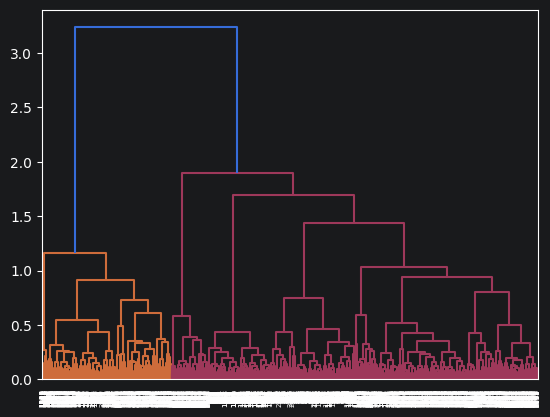

In [19]:
#sada klasterovanje
#dendogram
ward_linkage=sch.linkage(pdist(embeddings,metric='cosine'),method='ward')
sch.dendrogram(ward_linkage)

In [20]:
#vidim oda bi opimlani izbor klastera bi od 2 do 6
#sada proveriti to preko siluete skora
cos_dist=1-cosine_similarity(embeddings)
dist_clipped=np.clip(cos_dist,0,None)

In [24]:
for k in range(2,6):
    clusters=sch.fcluster(ward_linkage,t=k,criterion='maxclust')
    print(k,round(silhouette_score(dist_clipped,clusters,metric='precomputed',random_state=42),4))

2 0.2601
3 0.211
4 0.1233
5 0.1216


In [27]:
#vidimo da su vrednosti siluete skora dosta male samim tim pretpostavljam da se klusteri dosta preklapaju , vidimo da je najbolji silete skor za vrednost 2, ali kako je to malo dosadnu radicemo sa 3 klastera.

#siluete skor je za 3 klastea : 0.211


In [25]:
N_clust=3
df['cluster']=sch.fcluster(ward_linkage,t=N_clust,criterion='maxclust')
df.cluster.value_counts()

cluster
3    1647
1     650
2     186
Name: count, dtype: int64

In [ ]:
#podelili smo novosti u clustere vidimo da imamo dosta malo novina u 2 klasteru , najvise je u 3 klasteru cak 1647 .

In [26]:
df.cluster.value_counts(normalize=True)


cluster
3    0.663311
1    0.261780
2    0.074909
Name: proportion, dtype: float64

In [ ]:
#cak 66% novisti je zavrsil ou 3 klasteru , a 2 klaster cini samo 7% novina.

In [ ]:
#da vidim okoje su najbitnije reci .

In [30]:
keyword_ext=TfidfVectorizer(tokenizer=spacy_sredi_tekst,
        analyzer="word",
        stop_words='english',
        token_pattern=None,
        ngram_range=(1, 2),
        max_df=0.95,
        min_df=0.03,)

In [31]:
#da bi tfidf radio moramo prvo da ga fitujemo na celom review delu i onda da ga za pojediance novina samo transofrumujemo
model_keyword_ext=keyword_ext.fit(df['articleText_reduced'])

In [42]:
def get_top_ngrams(cluster):
    tekst=df[df['cluster']==cluster]['articleText_reduced']
    tfidf=model_keyword_ext.transform(tekst)
    reci=model_keyword_ext.get_feature_names_out()
    proseci=tfidf.mean(axis=0).A1
    rezultat=pd.Series(proseci,index=reci)
    rezultat=rezultat.drop(['say','year','new','good','like','time'],errors='ignore')
    return rezultat.nlargest(10).items()

In [ ]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = df['cluster'].nunique()
for i in range(n_clust):

    scored_kwds = get_top_ngrams(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)


fig.suptitle("Keywords across the news clusters")

plt.show()